In [20]:
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean

from functools import partial

In [6]:
plt.style.use("../../nice.mplstyle")

In [30]:
ds = xr.open_zarr("anemoi-hpx6-24h/dataset.zarr")
cds = xr.open_zarr("anemoi-hpx6-24h/obs_count_f32.zarr")

In [37]:
[x.replace("sla_filtered_", "") for x in ds.attrs["variables"]] == cds.attrs["variables"]

True

In [13]:
idx = ds.attrs["variables"].index("sla_filtered_topex_poseidon")

In [14]:
idx

27

In [18]:
tpx = ds.sel(variable=idx).squeeze()

In [ ]:
scatter = partial(
    plt.scatter,
    x=

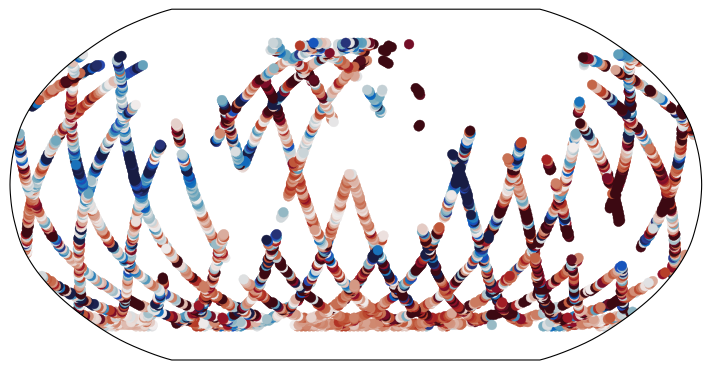

In [29]:
itime = 10

fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})

ax.scatter(
    tpx.longitudes,
    tpx.latitudes,
    c=tpx["data"].isel(time=itime).values,
    cmap="cmo.balance",
    vmin=-.1,
    vmax=.1,
    transform=ccrs.PlateCarree(),
)